In [ ]:

# Module 7 Lab 2: Restaurant Ratings Regression

# Use multiple linear regression to predict a restaurant's overall rating based on ambience, food, and service.

#


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

df = pd.read_csv("ratings.tsv", sep="\t")

print("Restaurant Ratings Dataset:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())


Restaurant Ratings Dataset:
   restaurant  food  ambience  service  rating
0           1    85        82       89      78
1           2    80        90       80      85
2           3    83        86       83      85
3           4    70        96       75      72
4           5    68        80       78      75

Dataset Shape:
(15, 5)

Column Names:
['restaurant', 'food', 'ambience', 'service', 'rating']


In [4]:

print("Missing Values:")
print(df.isnull().sum())

print("\nDataset Information:")
df.info()

# Select required columns
columns = ["ambience", "food", "service", "rating"]

# Convert columns to numeric
for col in columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows with missing values
df = df.dropna(subset=columns).copy()

print("\nCleaned Dataset:")
print(df.head())

print("\nRemaining Rows:", len(df))


Missing Values:
restaurant    0
food          0
ambience      0
service       0
rating        0
dtype: int64

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   restaurant  15 non-null     int64
 1   food        15 non-null     int64
 2   ambience    15 non-null     int64
 3   service     15 non-null     int64
 4   rating      15 non-null     int64
dtypes: int64(5)
memory usage: 732.0 bytes

Cleaned Dataset:
   restaurant  food  ambience  service  rating
0           1    85        82       89      78
1           2    80        90       80      85
2           3    83        86       83      85
3           4    70        96       75      72
4           5    68        80       78      75

Remaining Rows: 15


In [4]:

# Data Preparation

# I inspected the restaurant ratings dataset for missing values and incorrect data types. I converted the required columns to numeric values and removed rows containing missing values in the variables.


In [5]:

# Independent variables
X = df[["ambience", "food", "service"]]

# Dependent variable
y = df["rating"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())


Features:
   ambience  food  service
0        82    85       89
1        90    80       80
2        86    83       83
3        96    70       75
4        80    68       78

Target:
0    78
1    85
2    85
3    72
4    75
Name: rating, dtype: int64


In [6]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))


Training Samples: 12
Testing Samples: 3


In [7]:

model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

print("\nIntercept:")
print(round(model.intercept_, 4))

print("\nCoefficients:")
for feature, coefficient in zip(X.columns, model.coef_):
    print(f"{feature}: {coefficient:.4f}")


Linear Regression Model Trained Successfully!

Intercept:
-30.2845

Coefficients:
ambience: 0.0782
food: 0.8802
service: 0.4417


In [8]:

coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

coefficients = coefficients.sort_values(
    by="Coefficient",
    ascending=False
).reset_index(drop=True)

coefficients.index = coefficients.index + 1

print("Ranked Regression Coefficients:")
print(coefficients.round(4))

print("\nStrongest Positive Factor:")
print(coefficients.iloc[0]["Feature"])


Ranked Regression Coefficients:
    Feature  Coefficient
1      food       0.8802
2   service       0.4417
3  ambience       0.0782

Strongest Positive Factor:
food


In [9]:

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results:")
print(f"MAE: {mae:.4f}")
print(f"MSE: {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R-squared: {r2:.4f}")


Model Evaluation Results:
MAE: 5.1881
MSE: 51.9132
RMSE: 7.2051
R-squared: -76.8699


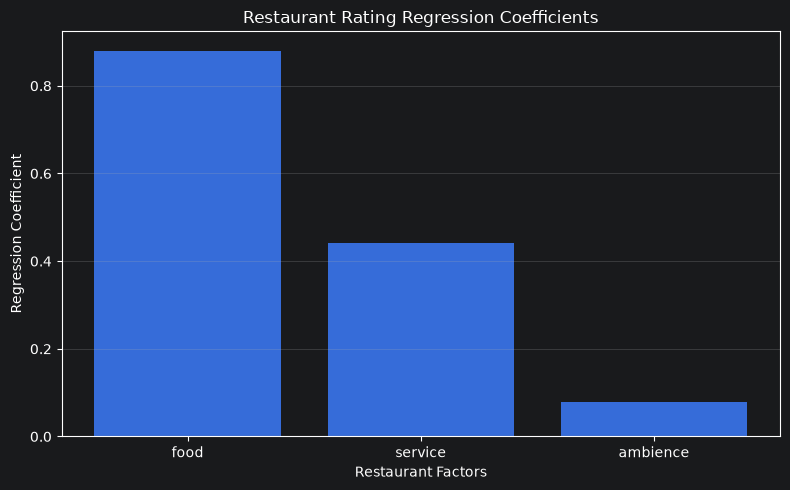

In [10]:

plt.figure(figsize=(8, 5))

plt.bar(
    coefficients["Feature"],
    coefficients["Coefficient"]
)

plt.title("Restaurant Rating Regression Coefficients")
plt.xlabel("Restaurant Factors")
plt.ylabel("Regression Coefficient")
plt.axhline(0, color="black", linewidth=0.8)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


In [11]:

positive_factors = coefficients[
    coefficients["Coefficient"] > 0
]

if not positive_factors.empty:
    strongest = positive_factors.iloc[0]["Feature"]
    strongest_coef = positive_factors.iloc[0]["Coefficient"]

    print("Business Recommendation:")
    print(
        f"The regression analysis identified {strongest} "
        f"as the strongest positive predictor of overall "
        f"restaurant ratings, with a coefficient of "
        f"{strongest_coef:.4f}."
    )
    print(
        f"A struggling restaurant should consider "
        f"prioritizing improvements in {strongest}, "
        f"while continuing to maintain food and service "
        f"quality."
    )
    print(
        "This relationship is predictive and does not "
        "prove that changing this factor will cause "
        "ratings to increase."
    )
else:
    print(
        "No factor has a positive fitted coefficient. "
        "Review the model and data before recommending "
        "an improvement priority."
    )


Business Recommendation:
The regression analysis identified food as the strongest positive predictor of overall restaurant ratings, with a coefficient of 0.8802.
A struggling restaurant should consider prioritizing improvements in food, while continuing to maintain food and service quality.
This relationship is predictive and does not prove that changing this factor will cause ratings to increase.
